# Predicting Electric Vehicle Purchases

Kaggle Playground Series S6E9 | Binary classification | ROC-AUC

I started with Logistic Regression and CatBoost as baselines before feature engineering or tuning.

Validation: 80/20 stratified split (seed 42). Test data is only used to generate predictions.

## Setup

In [12]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('catboost') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

RANDOM_STATE = 42
TARGET = "Will_Buy_EV"
EXPECTED_SHAPES = ((668665, 15), (286571, 14))

# Avoid picking up unrelated train.csv files.
locations = [Path("/kaggle/input/playground-series-s6e9"), Path("/content"), Path.cwd()]
data_dir = None
for root in locations:
    if not (root / "train.csv").is_file() or not (root / "test.csv").is_file():
        continue
    candidate_train = pd.read_csv(root / "train.csv")
    candidate_test = pd.read_csv(root / "test.csv")
    if (candidate_train.shape, candidate_test.shape) == EXPECTED_SHAPES:
        data_dir, train, test = root, candidate_train, candidate_test
        break
    print(f"Skipping {root}: wrong dataset shape {candidate_train.shape}, {candidate_test.shape}")
if data_dir is None:
    raise FileNotFoundError("Attach S6E9 data on Kaggle or upload its CSV files to /content or the notebook folder.")
print(f"Data directory: {data_dir}")
print(f"Train: {train.shape} | Test: {test.shape}")

In [14]:
assert TARGET in train.columns and TARGET not in test.columns
assert train.id.is_unique and test.id.is_unique
assert set(train.columns) - set(test.columns) == {TARGET}
assert set(train[TARGET].unique()) == {"No", "Yes"}
assert not train.isna().any().any() and not test.isna().any().any()
assert (train.shape, test.shape) == EXPECTED_SHAPES
display(train.head(3))
print("Training dtypes:")
print(train.dtypes.value_counts())

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes


Training dtypes:
object     7
int64      5
float64    3
Name: count, dtype: int64


## EDA

About 17.5% of rows are positive. I'll compare models using ROC-AUC rather than accuracy.

,count,percent
Will_Buy_EV,,
No,551886,82.54
Yes,116779,17.46


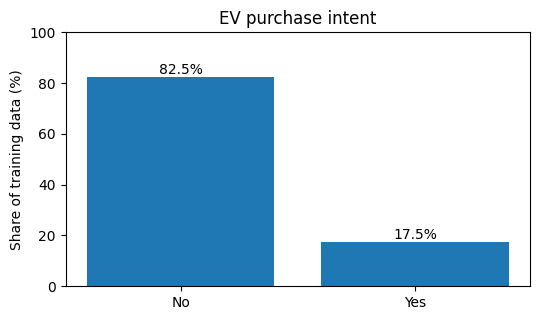

In [15]:
class_counts = train[TARGET].value_counts().reindex(["No", "Yes"])
class_rates = (class_counts / len(train) * 100).round(2)
display(pd.DataFrame({"count": class_counts, "percent": class_rates}))
fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.bar(class_rates.index, class_rates.values)
ax.set(ylabel="Share of training data (%)", title="EV purchase intent")
for i, value in enumerate(class_rates.values):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [16]:
# Compare purchase rates instead of just category counts.
eda = train.assign(target=train[TARGET].eq("Yes").astype(int))
key_cats = ["Subsidy_Available", "Range_Anxiety_Level", "Home_Charging_Possible", "City_Type"]
for feature in key_cats:
    rates = eda.groupby(feature)["target"].agg(["mean", "size"])
    rates["purchase_rate_pct"] = (100 * rates["mean"]).round(2)
    print(f"\n{feature}")
    display(rates[["size", "purchase_rate_pct"]].sort_values("purchase_rate_pct", ascending=False))


Subsidy_Available


,size,purchase_rate_pct
Subsidy_Available,,
Yes,419909,27.47
No,248756,0.58



Range_Anxiety_Level


,size,purchase_rate_pct
Range_Anxiety_Level,,
Low,603972,18.90
Medium,62499,4.17
High,2194,0.14



Home_Charging_Possible


,size,purchase_rate_pct
Home_Charging_Possible,,
Yes,462677,19.58
No,205988,12.71



City_Type


,size,purchase_rate_pct
City_Type,,
Rural,123983,19.34
Suburban,255377,18.09
Urban,289305,16.11


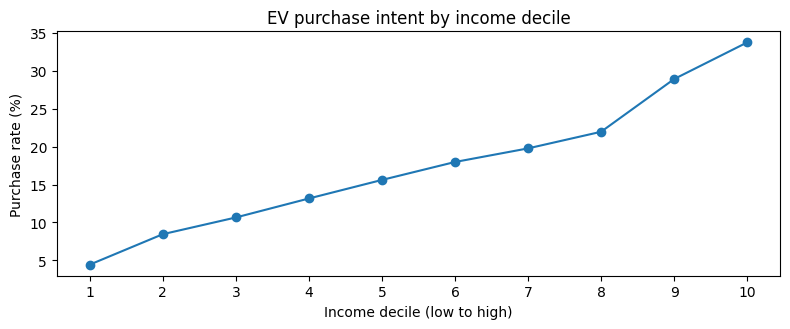

In [17]:
# Deciles make the income trend easier to read.
income_bins = pd.qcut(eda["Annual_Income_USD"], q=10, duplicates="drop")
income_rates = eda.groupby(income_bins, observed=True)["target"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(range(1, len(income_rates) + 1), income_rates.values, marker="o")
ax.set(xlabel="Income decile (low to high)", ylabel="Purchase rate (%)", title="EV purchase intent by income decile")
ax.set_xticks(range(1, len(income_rates) + 1))
plt.tight_layout()
plt.show()

In [18]:
interaction = pd.pivot_table(
    eda, values="target", index="Environmental_Concern_Level",
    columns="Subsidy_Available", aggfunc="mean"
) * 100
display(interaction.round(2).rename_axis("Environmental concern"))

Subsidy_Available,No,Yes
Environmental concern,,
1.0,0.02,0.94
2.0,0.05,3.48
3.0,0.30,18.66
4.0,0.81,39.94
5.0,2.48,69.33


Subsidy availability and environmental concern have the largest differences in purchase rates. Income also follows a trend. These are associations, not causal effects.

## Validation

Both baselines use the same stratified holdout. Test rows stay out of fitting and evaluation.

In [19]:
categorical_features = ["Gender", "City_Type", "Current_Car_Type", "Home_Charging_Possible", "Subsidy_Available", "Range_Anxiety_Level"]
X = train.drop(columns=["id", TARGET])
y = train[TARGET].map({"No": 0, "Yes": 1})
X_test = test.drop(columns="id")
assert X.columns.tolist() == X_test.columns.tolist()

# The same holdout is reused for every baseline comparison.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training:", X_train.shape, "Validation:", X_val.shape)
print("Positive class rates:", round(y_train.mean(), 4), round(y_val.mean(), 4))

Training: (534932, 13) Validation: (133733, 13)
Positive class rates: 0.1746 0.1746


## Logistic Regression

Linear baseline. Scaling and one-hot encoding are fitted inside the pipeline, using training rows only.

In [20]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])
log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
log_model.fit(X_train, y_train)
log_probs = log_model.predict_proba(X_val)[:, 1]
log_auc = roc_auc_score(y_val, log_probs)
print(f"Logistic Regression ROC-AUC: {log_auc:.6f}")

Logistic Regression ROC-AUC: 0.937958


## CatBoost

CatBoost handles categorical columns directly. I use early stopping on the validation split to choose the tree count.

In [21]:
cat_model = CatBoostClassifier(
    iterations=1000, learning_rate=0.05, depth=7,
    loss_function="Logloss", eval_metric="AUC",
    random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
    thread_count=4
)
cat_model.fit(
    X_train, y_train, cat_features=categorical_features,
    eval_set=(X_val, y_val), early_stopping_rounds=100, verbose=False
)
cat_probs = cat_model.predict_proba(X_val)[:, 1]
cat_auc = roc_auc_score(y_val, cat_probs)
print(f"CatBoost ROC-AUC: {cat_auc:.6f}")
print("Best iteration (zero-indexed):", cat_model.get_best_iteration())

CatBoost ROC-AUC: 0.941471
Best iteration (zero-indexed): 985


## Results

In [22]:
results = pd.DataFrame({
    "model": ["Logistic Regression", "CatBoost"],
    "validation_roc_auc": [log_auc, cat_auc]
}).sort_values("validation_roc_auc", ascending=False)
display(results.style.format({"validation_roc_auc": "{:.6f}"}))
print(f"CatBoost minus Logistic Regression: {cat_auc - log_auc:+.6f}")

,model,validation_roc_auc
1,CatBoost,0.941471
0,Logistic Regression,0.937958


CatBoost minus Logistic Regression: +0.003513


,CatBoost importance
Subsidy_Available,53.356670
Environmental_Concern_Level,19.065091
Annual_Income_USD,10.265797
Range_Anxiety_Level,3.842667
Age,3.291979
Daily_Commute_km,3.227811
Charging_Stations_Near_Home,2.017165
Charging_Stations_Near_Work,1.900340
Home_Charging_Possible,1.031251
Number_of_Cars_Owned,0.753725


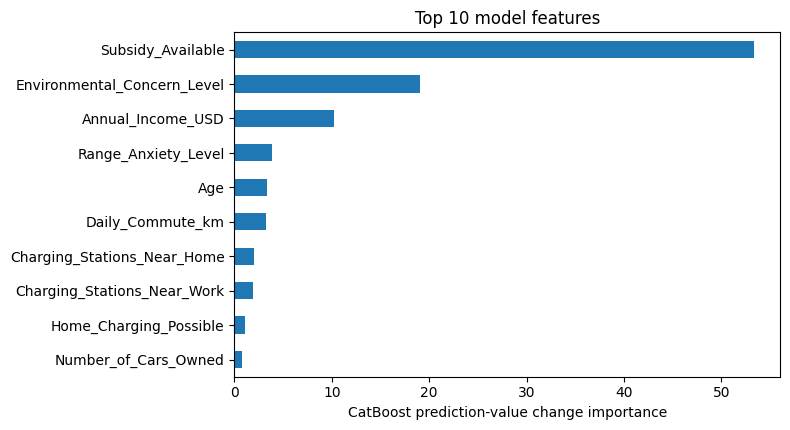

In [23]:
importance = pd.Series(
    cat_model.get_feature_importance(), index=X_train.columns
).sort_values(ascending=False)
display(importance.rename("CatBoost importance").to_frame().head(10))
fig, ax = plt.subplots(figsize=(8, 4.4))
importance.head(10).sort_values().plot.barh(ax=ax)
ax.set(xlabel="CatBoost prediction-value change importance", title="Top 10 model features")
plt.tight_layout()
plt.show()

Subsidy availability is the strongest CatBoost feature by model importance, followed by environmental concern and income. That does not imply causality.

This is a single holdout, and CatBoost also uses it for early stopping. I'll use cross-validation before tuning more seriously.

## Submission

I refit the stronger baseline on all labeled training rows and submit the predicted probability of `Yes`.

In [ ]:
if cat_auc >= log_auc:
    final_model = CatBoostClassifier(
        iterations=max(1, cat_model.get_best_iteration() + 1),
        learning_rate=0.05, depth=7, loss_function="Logloss",
        random_seed=RANDOM_STATE, verbose=False,
        allow_writing_files=False, thread_count=4
    )
    final_model.fit(X, y, cat_features=categorical_features, verbose=False)
    test_probs = final_model.predict_proba(X_test)[:, 1]
    chosen_model = "CatBoost"
else:
    final_model = Pipeline([
        ("preprocessor", ColumnTransformer([
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ])),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
    final_model.fit(X, y)
    test_probs = final_model.predict_proba(X_test)[:, 1]
    chosen_model = "Logistic Regression"

submission = pd.DataFrame({"id": test["id"], TARGET: test_probs})
assert submission.shape == (len(test), 2)
assert submission[TARGET].between(0, 1).all()
assert submission.notna().all().all()
submission.to_csv("submission.csv", index=False)
print("Selected model:", chosen_model)
print("Saved submission.csv:", submission.shape)
display(submission.head())

Selected model: CatBoost
Saved submission.csv: (286571, 2)


,id,Will_Buy_EV
0,668665,0.009541
1,668666,0.023244
2,668667,0.004034
3,668668,0.002434
4,668669,0.022711
